# Amazon Bestselling Books Genre Classification

## Problem Statement

The objective of this project is to build a machine learning classification model that predicts whether an Amazon bestselling book belongs to the **Fiction** or **Non Fiction** genre.

The dataset contains information such as user rating, number of reviews, book price, publication/bestseller year, author, book name, and genre.

Since `Genre` contains two categories, this is a **Binary Classification Problem**.

The project follows an end-to-end machine learning workflow including:
- Dataset understanding
- Exploratory Data Analysis
- Data cleaning
- Outlier analysis
- Feature engineering
- Feature selection
- Train-test splitting
- Building five machine learning models
- Cross-validation
- Model evaluation and comparison
- Hyperparameter tuning
- Best model selection
- Prediction on unseen data
- Final conclusion

### 5W Explanation

- **What:** A binary classification project that predicts whether an Amazon bestselling book is **Fiction** or **Non Fiction**.
- **Why:** To demonstrate a complete, explainable machine-learning workflow from raw data understanding to a reliable genre classifier.
- **Who:** The analysis is designed for a data analyst / machine-learning engineer and for stakeholders who want to understand what characteristics are associated with book genre.
- **When:** This problem definition is established before any data cleaning, EDA, feature engineering, or model building begins.
- **Where:** The work is performed on the Amazon bestselling-books dataset, using `Genre` as the target variable.


## Importing Required Libraries

In this section, the libraries required for data manipulation, visualization, preprocessing, model building, validation, evaluation, and model saving are imported.

Pandas and NumPy are used for data handling. Matplotlib and Seaborn are used for visualization. Scikit-learn is used for machine learning algorithms and evaluation.

### 5W Explanation

- **What:** Import the Python libraries needed for data handling, visualization, preprocessing, modeling, validation, evaluation, and model saving.
- **Why:** Each later step depends on these packages, so loading them once keeps the workflow organized and reproducible.
- **Who:** The data analyst / ML engineer uses these libraries to perform the complete project.
- **When:** This is done at the very beginning, before the dataset is loaded or analyzed.
- **Where:** The imports are executed in the notebook environment and are used by all later cells.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

## Loading the Dataset

The dataset is loaded using Pandas. After loading the file, the first five records are displayed to understand its structure.

Each row represents a bestselling book entry and the target variable is `Genre`.

### 5W Explanation

- **What:** Load the Amazon bestselling-books CSV file into a Pandas DataFrame and preview the first records.
- **Why:** The model cannot be developed until the raw data is available in a structured form and its columns can be inspected.
- **Who:** The ML engineer loads the source dataset and checks that it has been read correctly.
- **When:** Immediately after importing the required libraries.
- **Where:** The CSV file is loaded into the notebook as the DataFrame `df`.


In [2]:
df = pd.read_csv("bestsellers with categories.csv")

df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


## Dataset Dimensions

The shape of the dataset is checked to determine the total number of rows and columns.

This helps us understand the size of the available data before preprocessing and model development.

### 5W Explanation

- **What:** Check the number of rows and columns in the dataset.
- **Why:** Dataset size helps determine how much information is available and whether the modeling approach is reasonable.
- **Who:** The analyst uses this check to understand the amount of data available for training and testing.
- **When:** Right after loading the dataset and before deeper exploration.
- **Where:** The check is performed on the complete DataFrame `df`.


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 550
Number of columns: 7


## Dataset Information

The `info()` function displays the column names, data types, number of non-null values, and memory usage.

This is useful for identifying categorical and numerical variables and checking whether any columns contain missing values.

### 5W Explanation

- **What:** Inspect column names, data types, non-null counts, and memory usage using `df.info()`.
- **Why:** This reveals the structure of the dataset and quickly identifies data-type or missing-value issues.
- **Who:** The analyst / ML engineer uses this information to plan preprocessing.
- **When:** During the initial dataset-understanding stage.
- **Where:** The inspection is applied to all columns of the loaded DataFrame.


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    str    
 1   Author       550 non-null    str    
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 68.7 KB


## Understanding the Features

The column names are displayed so that the input features and target variable can be identified.

The target variable for this project is `Genre`.

### 5W Explanation

- **What:** Display all column names and identify potential input variables and the target variable.
- **Why:** Clear feature and target identification prevents accidental use of the wrong columns during modeling.
- **Who:** The ML engineer decides which columns may be useful predictors and which column must be predicted.
- **When:** Before statistical analysis, feature engineering, and feature selection.
- **Where:** The feature names come directly from the Amazon bestseller DataFrame.


In [5]:
print(df.columns.tolist())

['Name', 'Author', 'User Rating', 'Reviews', 'Price', 'Year', 'Genre']


## Descriptive Statistics

Descriptive statistics are calculated for numerical variables.

This provides information such as mean, standard deviation, minimum, maximum, and quartile values. It helps identify the scale, distribution, and possible extreme values in numerical features.

### 5W Explanation

- **What:** Calculate summary statistics for the numerical columns.
- **Why:** Mean, spread, quartiles, minimum, and maximum help reveal scale differences, skewness, and possible extreme values.
- **Who:** The analyst uses these statistics to understand numerical behavior before preprocessing.
- **When:** During exploratory data analysis, before transforming features or training models.
- **Where:** The statistics are computed for the numerical columns in `df`.


In [6]:
df.describe()

,User Rating,Reviews,Price,Year
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


## Checking Missing Values

Missing values can affect machine learning algorithms and may require removal or imputation.

The number of missing values is calculated for every column. If no missing values are found, no imputation is required.

### 5W Explanation

- **What:** Count missing values in every column.
- **Why:** Missing data can break or bias machine-learning algorithms and must be handled before model training.
- **Who:** The analyst checks whether imputation or row/column removal is necessary.
- **When:** During data-quality assessment before feature engineering and splitting.
- **Where:** The check is performed across every column in the full dataset.


In [7]:
missing_values = df.isnull().sum()

print(missing_values)

Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64


## Checking Duplicate Records

Duplicate rows may unnecessarily repeat the same observation and can affect the learning process.

Exact duplicate rows are identified and removed only if they exist.

### 5W Explanation

- **What:** Detect exact duplicate rows and remove them only if they exist.
- **Why:** Exact duplicates can overweight repeated observations and distort model learning.
- **Who:** The analyst performs this cleaning decision while preserving valid repeated bestseller entries.
- **When:** After missing-value inspection and before modeling.
- **Where:** The duplicate check is applied to the complete DataFrame `df`.


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
else:
    print("No exact duplicate rows found.")

Number of exact duplicate rows: 0
No exact duplicate rows found.


## Checking Repeated Book Names

Some books may appear multiple times because they were bestsellers in different years. These should not automatically be considered duplicate records because the year associated with each observation may be different.

Therefore, repeated book names are examined but are not deleted blindly.

### 5W Explanation

- **What:** Compare total records with unique book names to identify books that appear more than once.
- **Why:** A repeated title may be a legitimate bestseller in multiple years and should not automatically be treated as a duplicate.
- **Who:** The analyst distinguishes valid repeated observations from exact duplicate rows.
- **When:** After exact duplicate checking and before feature engineering.
- **Where:** The check focuses on the `Name` column of the bestseller dataset.


In [9]:
print("Unique book names:", df["Name"].nunique())
print("Total records:", len(df))

repeated_books = df[df["Name"].duplicated(keep=False)]

repeated_books.sort_values("Name").head(10)

Unique book names: 351
Total records: 550


,Name,Author,User Rating,Reviews,Price,Year,Genre
9,A Man Called Ove: A Novel,Fredrik Backman,4.6,23848,8,2016,Fiction
10,A Man Called Ove: A Novel,Fredrik Backman,4.6,23848,8,2017,Fiction
20,All the Light We Cannot See,Anthony Doerr,4.6,36348,14,2014,Fiction
21,All the Light We Cannot See,Anthony Doerr,4.6,36348,14,2015,Fiction
32,Becoming,Michelle Obama,4.8,61133,11,2018,Non Fiction
33,Becoming,Michelle Obama,4.8,61133,11,2019,Non Fiction
35,Between the World and Me,Ta-Nehisi Coates,4.7,10070,13,2015,Non Fiction
36,Between the World and Me,Ta-Nehisi Coates,4.7,10070,13,2016,Non Fiction
40,"Brown Bear, Brown Bear, What Do You See?",Bill Martin Jr.,4.9,14344,5,2017,Fiction
41,"Brown Bear, Brown Bear, What Do You See?",Bill Martin Jr.,4.9,14344,5,2019,Fiction


## Distribution of Target Variable

The frequency of each genre is examined to understand the class distribution.

A classification dataset with extremely unequal classes may require techniques for handling class imbalance. Here, the distribution is checked before deciding whether such techniques are necessary.

### 5W Explanation

- **What:** Count the number of `Fiction` and `Non Fiction` target observations.
- **Why:** Class distribution determines whether class imbalance could affect model training and evaluation.
- **Who:** The ML engineer uses the class counts to decide whether balancing techniques are needed.
- **When:** Before the train-test split and model construction.
- **Where:** The analysis is performed on the target column `Genre`.


In [10]:
print(df["Genre"].value_counts())

print("\nPercentage Distribution:")
print(df["Genre"].value_counts(normalize=True) * 100)

Genre
Non Fiction    310
Fiction        240
Name: count, dtype: int64

Percentage Distribution:
Genre
Non Fiction    56.363636
Fiction        43.636364
Name: proportion, dtype: float64


## Visualization of Genre Distribution

A count plot is used to visually compare the number of Fiction and Non Fiction books.

The graph shows that the classes are reasonably balanced, although Non Fiction contains slightly more observations.

### 5W Explanation

- **What:** Visualize the number of books in each genre using a count plot.
- **Why:** A chart makes class balance easier to interpret than counts alone.
- **Who:** The analyst and project reviewer can visually inspect the target balance.
- **When:** Immediately after calculating genre frequencies.
- **Where:** The visualization uses the `Genre` column from the full dataset.


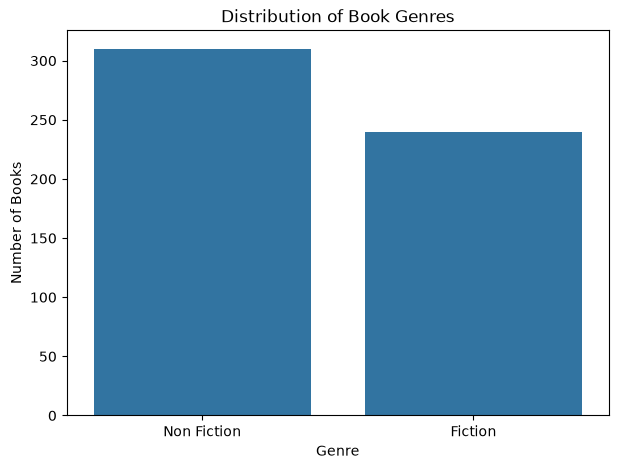

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Genre")

plt.title("Distribution of Book Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Books")

plt.show()

## Distribution of Numerical Features

Histograms are used to examine the distributions of User Rating, Reviews, Price, and Year.

This analysis helps identify skewness, concentration of values, and possible outliers before model development.

### 5W Explanation

- **What:** Plot histograms for User Rating, Reviews, Price, and Year.
- **Why:** Distribution plots help reveal skewness, concentration, unusual values, and feature-scale differences.
- **Who:** The analyst uses these plots to decide whether transformations or special handling are needed.
- **When:** During EDA before outlier analysis and feature engineering.
- **Where:** The plots use the dataset's numerical columns.


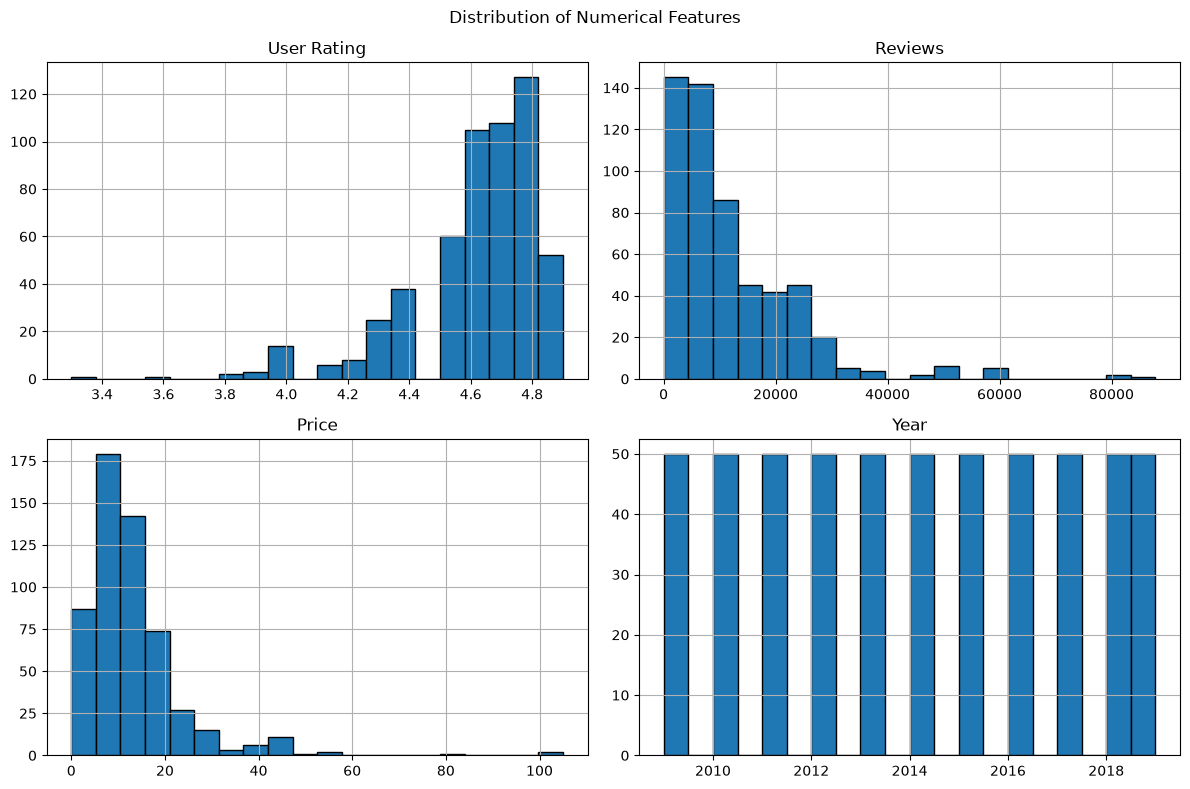

In [12]:
numerical_columns = ["User Rating", "Reviews", "Price", "Year"]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

## Outlier Analysis

Boxplots are used to identify possible extreme values in numerical variables.

Reviews and Price contain some observations that appear as outliers. However, these values can represent genuinely popular or expensive bestselling books. Removing them without evidence could result in loss of meaningful information.

Therefore, the values are examined rather than automatically deleted.

### 5W Explanation

- **What:** Use boxplots to visually inspect possible outliers in the numerical features.
- **Why:** Outliers can influence some models, but genuine extreme bestseller values should not be deleted without evidence.
- **Who:** The analyst evaluates whether extreme observations are errors or meaningful real-world values.
- **When:** After reviewing feature distributions and before transformation decisions.
- **Where:** The analysis covers User Rating, Reviews, Price, and Year.


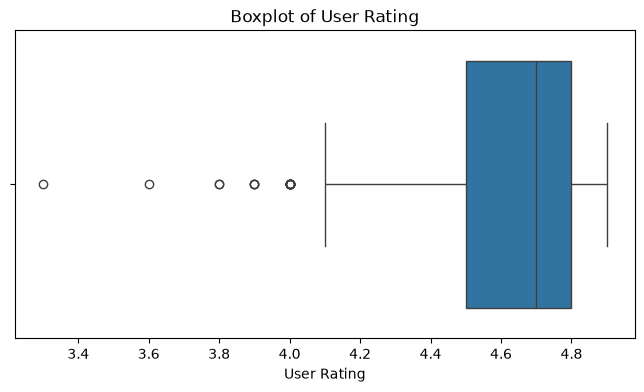

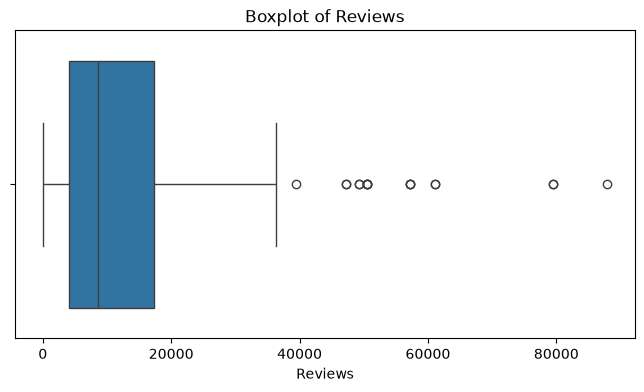

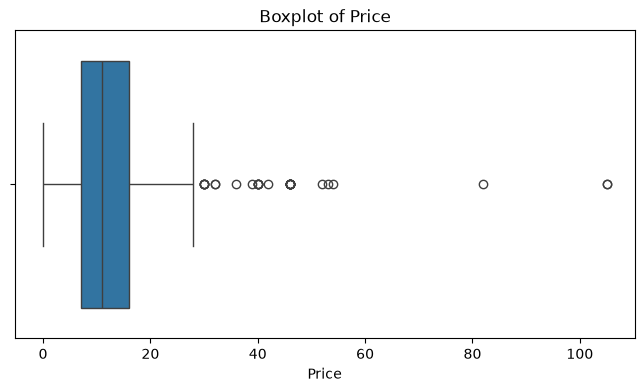

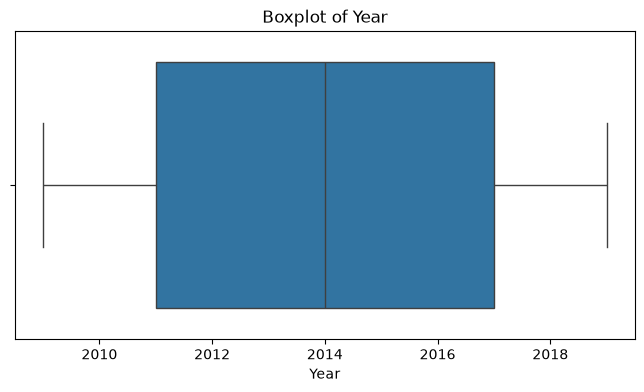

In [13]:
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot of {column}")

    plt.show()

## Detecting Outliers Using IQR

The Interquartile Range method is used to count observations lying outside the conventional lower and upper boundaries.

The purpose of this step is to understand the presence of extreme observations rather than automatically remove them. Extreme review counts and prices can be valid characteristics of bestselling books.

### 5W Explanation

- **What:** Count potential outliers with the Interquartile Range (IQR) rule.
- **Why:** A numerical rule complements boxplots and quantifies how many observations fall beyond conventional bounds.
- **Who:** The analyst uses the count to make an informed decision rather than removing values blindly.
- **When:** After visual outlier inspection.
- **Where:** The IQR calculation is applied to the selected numerical columns.


In [14]:
def count_outliers(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return len(outliers)


for column in numerical_columns:
    print(
        column,
        ":",
        count_outliers(df, column),
        "potential outliers"
    )

User Rating : 21 potential outliers
Reviews : 17 potential outliers
Price : 31 potential outliers
Year : 0 potential outliers


## User Rating by Genre

A boxplot is used to compare user ratings between Fiction and Non Fiction books.

This helps determine whether user rating may contain useful information for distinguishing between the two classes.

### 5W Explanation

- **What:** Compare the distribution of user ratings between Fiction and Non Fiction.
- **Why:** Differences between classes can indicate whether `User Rating` has predictive value.
- **Who:** The ML engineer evaluates whether this feature should remain in the model.
- **When:** During class-wise EDA before feature selection.
- **Where:** The comparison uses `User Rating` grouped by `Genre`.


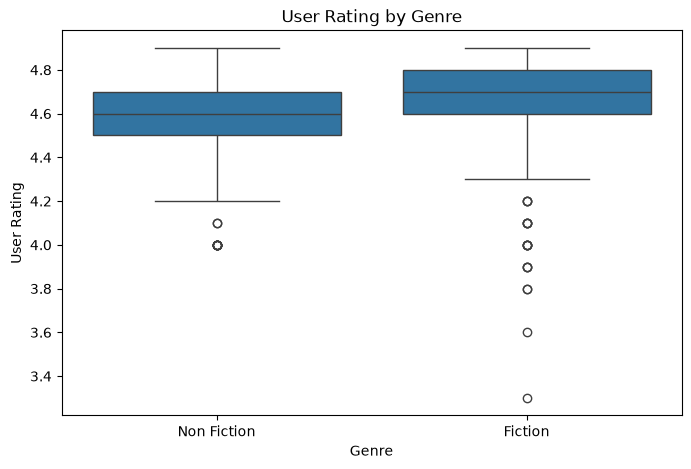

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Genre",
    y="User Rating"
)

plt.title("User Rating by Genre")

plt.show()

## Review Count by Genre

The number of reviews is compared across genres.

Since the Reviews feature contains very large values and is highly skewed, the visualization helps motivate a logarithmic transformation later during feature engineering.

### 5W Explanation

- **What:** Compare review counts between Fiction and Non Fiction books.
- **Why:** The comparison helps assess predictive value and also highlights the strong skewness of review counts.
- **Who:** The analyst uses the pattern to motivate later transformation of the Reviews feature.
- **When:** During class-wise EDA before feature engineering.
- **Where:** The analysis uses `Reviews` grouped by `Genre`.


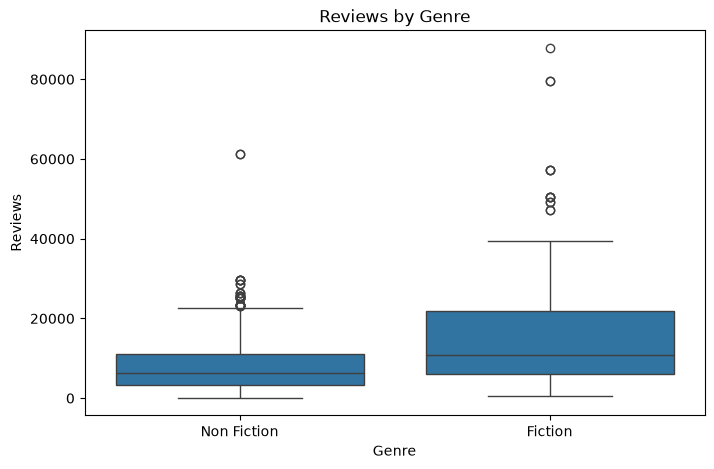

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Genre",
    y="Reviews"
)

plt.title("Reviews by Genre")

plt.show()

## Book Price by Genre

Book prices are compared between Fiction and Non Fiction categories.

Differences in the distribution of prices may provide useful information to the classification algorithms.

### 5W Explanation

- **What:** Compare book-price distributions across the two genre classes.
- **Why:** Different price patterns may help models distinguish Fiction from Non Fiction.
- **Who:** The analyst evaluates `Price` as a possible predictive feature.
- **When:** During EDA before final feature selection.
- **Where:** The comparison uses `Price` grouped by `Genre`.


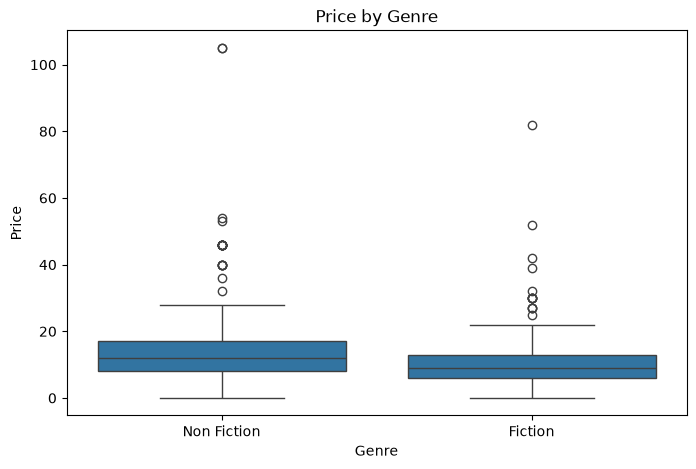

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Genre",
    y="Price"
)

plt.title("Price by Genre")

plt.show()

## Correlation Analysis

A correlation heatmap is created for numerical variables.

Correlation analysis helps understand relationships between numerical features and identify whether any features are strongly correlated with each other.

### 5W Explanation

- **What:** Calculate and visualize correlations among numerical variables.
- **Why:** Correlation helps identify relationships and possible redundancy among predictors.
- **Who:** The analyst uses the correlation matrix to understand feature interactions before selecting model inputs.
- **When:** Near the end of EDA, before feature engineering and selection.
- **Where:** The heatmap is based on the numerical columns of the dataset.


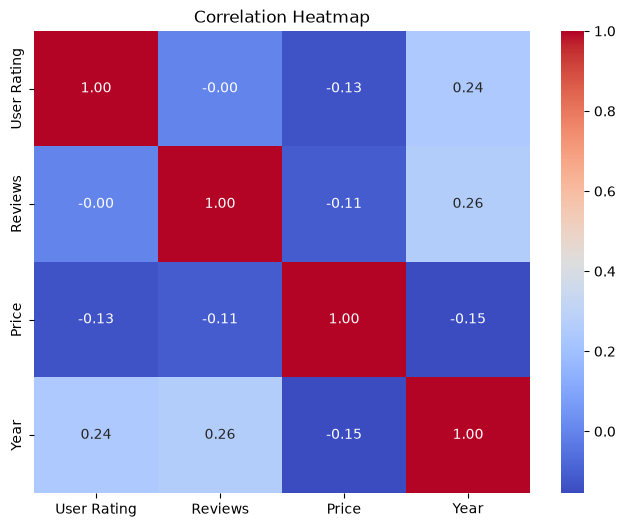

In [18]:
plt.figure(figsize=(8, 6))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Feature Engineering

The `Reviews` variable is strongly right-skewed because some bestselling books receive extremely large numbers of reviews.

Instead of deleting these observations, a logarithmic transformation is applied using `log1p`. This reduces the effect of extremely large values while preserving all observations.

A new feature called `Reviews_Log` is created and used for model training.

### 5W Explanation

- **What:** Create `Reviews_Log` by applying `np.log1p()` to the original Reviews values.
- **Why:** The transformation reduces right skew and the influence of extremely large review counts while keeping every observation.
- **Who:** The ML engineer creates this engineered feature to make the review information easier for several algorithms to use.
- **When:** After EDA shows that Reviews is strongly right-skewed.
- **Where:** The new `Reviews_Log` column is added to the existing DataFrame.


In [19]:
df["Reviews_Log"] = np.log1p(df["Reviews"])

df[["Reviews", "Reviews_Log"]].head()

,Reviews,Reviews_Log
0,17350,9.761405
1,2052,7.627057
2,18979,9.851141
3,21424,9.972314
4,7665,8.944550


## Effect of Log Transformation

The original Reviews distribution and logarithmically transformed distribution are compared.

The transformed feature is expected to have reduced right skewness, making it more suitable for algorithms that are sensitive to feature distributions and distances.

### 5W Explanation

- **What:** Compare the original Reviews distribution with the transformed `Reviews_Log` distribution.
- **Why:** The comparison verifies whether the transformation reduces skewness as intended.
- **Who:** The analyst checks the effect before using the transformed feature in model training.
- **When:** Immediately after creating `Reviews_Log`.
- **Where:** Both distributions are visualized from columns in `df`.


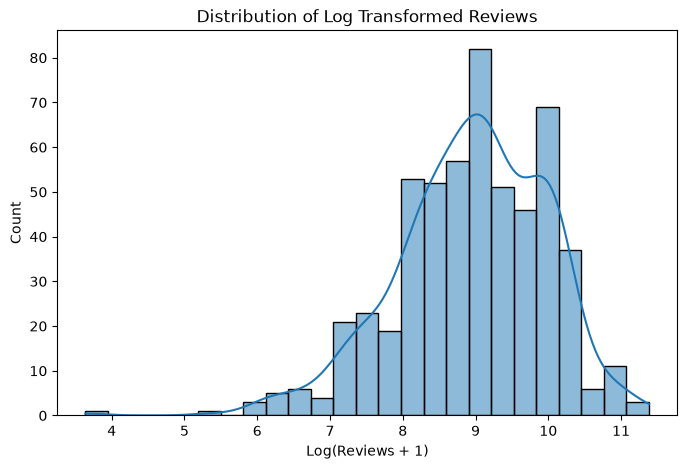

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Reviews_Log"],
    bins=25,
    kde=True
)

plt.title("Distribution of Log Transformed Reviews")
plt.xlabel("Log(Reviews + 1)")

plt.show()

## Feature Selection

The target variable is `Genre`.

For this tabular classification model, the following numerical predictors are selected:

- User Rating
- Reviews_Log
- Price
- Year

`Name` and `Author` are not included because they are high-cardinality text variables. Directly label-encoding such variables could introduce artificial numerical relationships between unrelated book names or authors.

Natural Language Processing techniques could be used for these columns in a separate text-classification project, but they are not required for this numerical classification workflow.

### 5W Explanation

- **What:** Use User Rating, Reviews_Log, Price, and Year as model inputs, with `Genre` as the target.
- **Why:** These numerical features are directly usable, while high-cardinality Name and Author text fields could create misleading relationships if naively encoded.
- **Who:** The ML engineer defines the final input matrix `X` and target vector `y`.
- **When:** After EDA and feature engineering, just before splitting the data.
- **Where:** Selected columns are taken from the cleaned and engineered DataFrame.


In [21]:
features = [
    "User Rating",
    "Reviews_Log",
    "Price",
    "Year"
]

X = df[features]

y = df["Genre"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Input shape: (550, 4)
Target shape: (550,)


,User Rating,Reviews_Log,Price,Year
0,4.7,9.761405,8,2016
1,4.6,7.627057,22,2011
2,4.7,9.851141,15,2018
3,4.7,9.972314,6,2017
4,4.8,8.944550,12,2019


## Train-Test Split

The dataset is divided into training and testing sets.

80% of the data is used for model training and 20% is reserved for final testing.

`stratify=y` is used so that approximately the same Fiction and Non Fiction class proportions are maintained in both datasets.

A fixed `random_state` makes the experiment reproducible.

### 5W Explanation

- **What:** Split the selected data into 80% training data and 20% testing data using stratification.
- **Why:** Training data is used to learn the models, while the untouched test set provides an independent final evaluation.
- **Who:** The ML engineer creates the split for fair and reproducible model development.
- **When:** After all preprocessing and feature selection are completed and before any model is trained.
- **Where:** `X` and `y` are divided into `X_train`, `X_test`, `y_train`, and `y_test` with `random_state=42` and `stratify=y`.


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 440
Testing samples: 110

Training target distribution:
Genre
Non Fiction    248
Fiction        192
Name: count, dtype: int64

Testing target distribution:
Genre
Non Fiction    62
Fiction        48
Name: count, dtype: int64


## Modeling Plan After the Train-Test Split

From this point onward, all five algorithms are handled **separately**. Each model receives baseline training, test evaluation, 5-fold stratified cross-validation, GridSearchCV hyperparameter tuning, tuned-model evaluation, and a baseline-vs-tuned comparison. The same split is reused for fairness.

### 5W Explanation

- **What:** Apply one complete and consistent workflow to all five classifiers.
- **Why:** Using the same workflow makes every model directly comparable.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after the fixed train-test split.
- **Where:** Training and validation use `X_train`/`y_train`; final testing uses `X_test`/`y_test`.


In [23]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold Stratified Cross-Validation is ready.")

5-fold Stratified Cross-Validation is ready.


## Model 1 — Logistic Regression: Baseline Model

Logistic Regression is a simple linear classifier. Scaling is included because its optimization is affected by feature scale.

### 5W Explanation

- **What:** Build and fit the baseline Logistic Regression classifier.
- **Why:** It gives an interpretable linear baseline before trying more flexible nonlinear models.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Before evaluating, validating, and tuning Logistic Regression.
- **Where:** The model is fitted on the fixed training set created above.


In [24]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression baseline model trained.")

Logistic Regression baseline model trained.


## Logistic Regression — Baseline Evaluation Metrics

The baseline model is evaluated with training accuracy, test accuracy, weighted precision, weighted recall, weighted F1-score, a class-wise classification report, and a confusion matrix heatmap.

### 5W Explanation

- **What:** Measure the baseline Logistic Regression on both training and unseen test data.
- **Why:** Multiple metrics provide a fuller picture than accuracy alone, while the train-test gap helps reveal overfitting or underfitting.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after fitting baseline Logistic Regression.
- **Where:** Predictions are generated from the fixed training and test sets.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,0.6818,0.6091,0.6026,0.6091,0.597



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.57      0.42      0.48        48
 Non Fiction       0.63      0.76      0.69        62

    accuracy                           0.61       110
   macro avg       0.60      0.59      0.58       110
weighted avg       0.60      0.61      0.60       110



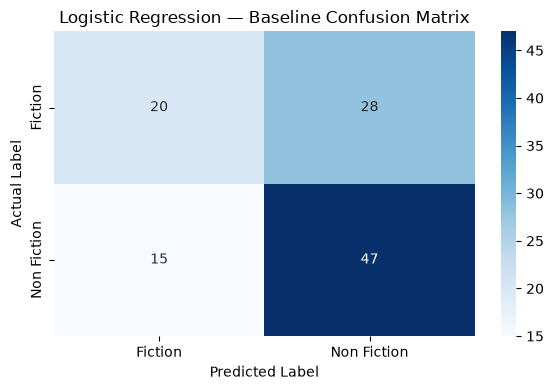

In [25]:
logistic_train_pred = logistic_model.predict(X_train)
logistic_test_pred = logistic_model.predict(X_test)

logistic_baseline_metrics = {
    "Train Accuracy": accuracy_score(y_train, logistic_train_pred),
    "Test Accuracy": accuracy_score(y_test, logistic_test_pred),
    "Precision": precision_score(y_test, logistic_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, logistic_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, logistic_test_pred, average="weighted", zero_division=0)
}

display(pd.DataFrame([logistic_baseline_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, logistic_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, logistic_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Logistic Regression — Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Logistic Regression — Validation

Five-fold stratified cross-validation is performed only on the training data using weighted F1-score. Fold scores, mean score, and standard deviation are reported.

### 5W Explanation

- **What:** Validate baseline Logistic Regression across five stratified folds.
- **Why:** Cross-validation checks whether its linear performance is stable across different training subsets.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Logistic Regression test evaluation and before hyperparameter tuning.
- **Where:** Cross-validation uses only the training data; the test set remains untouched.


In [26]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

logistic_baseline_cv_mean = logistic_cv_scores.mean()
logistic_baseline_cv_std = logistic_cv_scores.std()

print("Fold F1 Scores:", np.round(logistic_cv_scores, 4))
print("Mean CV F1:", round(logistic_baseline_cv_mean, 4))
print("CV Standard Deviation:", round(logistic_baseline_cv_std, 4))

Fold F1 Scores: [0.6414 0.6386 0.7382 0.6916 0.6901]
Mean CV F1: 0.68
CV Standard Deviation: 0.037


## Logistic Regression — Hyperparameter Tuning

The regularization strength `C` and solver are tuned. GridSearchCV uses the same five-fold stratified validation and weighted F1-score.

### 5W Explanation

- **What:** Search for a stronger Logistic Regression configuration.
- **Why:** Regularization controls model flexibility and may improve generalization.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Logistic Regression validation.
- **Where:** The parameter search is performed only on the training data.


In [27]:
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best Parameters:", logistic_grid.best_params_)
print("Best Validation F1:", round(logistic_grid.best_score_, 4))

Best Parameters: {'model__C': 1, 'model__solver': 'lbfgs'}
Best Validation F1: 0.68


## Logistic Regression — Tuned Model Evaluation

The best estimator returned by GridSearchCV is evaluated with the same train/test metrics, classification report, confusion matrix heatmap, and five-fold validation used for the baseline.

### 5W Explanation

- **What:** Measure the tuned Logistic Regression using exactly the same evaluation framework.
- **Why:** Identical evaluation allows a fair baseline-vs-tuned comparison.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after Logistic Regression hyperparameter tuning.
- **Where:** Test metrics use the untouched test set; validation uses the training set.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,0.6818,0.6091,0.6026,0.6091,0.597,0.68,0.037



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.57      0.42      0.48        48
 Non Fiction       0.63      0.76      0.69        62

    accuracy                           0.61       110
   macro avg       0.60      0.59      0.58       110
weighted avg       0.60      0.61      0.60       110



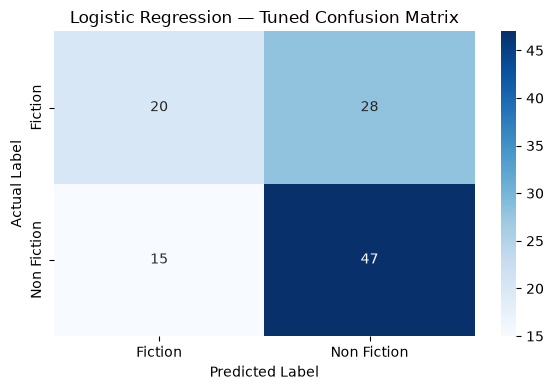

In [28]:
tuned_logistic = logistic_grid.best_estimator_

tuned_logistic_train_pred = tuned_logistic.predict(X_train)
tuned_logistic_test_pred = tuned_logistic.predict(X_test)

tuned_logistic_cv_scores = cross_val_score(
    tuned_logistic, X_train, y_train, cv=cv, scoring="f1_weighted"
)

logistic_tuned_metrics = {
    "Train Accuracy": accuracy_score(y_train, tuned_logistic_train_pred),
    "Test Accuracy": accuracy_score(y_test, tuned_logistic_test_pred),
    "Precision": precision_score(y_test, tuned_logistic_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, tuned_logistic_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, tuned_logistic_test_pred, average="weighted", zero_division=0),
    "CV F1 Mean": tuned_logistic_cv_scores.mean(),
    "CV F1 Std": tuned_logistic_cv_scores.std()
}

display(pd.DataFrame([logistic_tuned_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_logistic_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, tuned_logistic_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Logistic Regression — Tuned Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Logistic Regression — Baseline vs Tuned Comparison

Baseline and tuned results are placed side by side across training accuracy, test metrics, and validation scores.

### 5W Explanation

- **What:** Compare Logistic Regression before and after tuning.
- **Why:** Tuning should be justified by measured improvement rather than assumed to help.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After tuned Logistic Regression evaluation.
- **Where:** The table uses metrics from the same data split and validation strategy.


,Version,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Baseline,0.6818,0.6091,0.6026,0.6091,0.597,0.68,0.037
1,Tuned,0.6818,0.6091,0.6026,0.6091,0.597,0.68,0.037


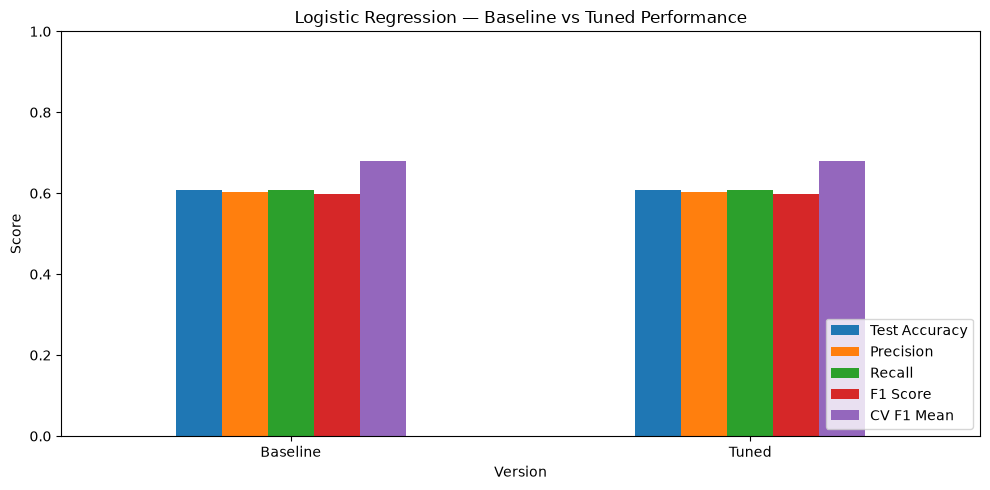

In [29]:
logistic_comparison = pd.DataFrame([
    {
        "Version": "Baseline",
        **logistic_baseline_metrics,
        "CV F1 Mean": logistic_baseline_cv_mean,
        "CV F1 Std": logistic_baseline_cv_std
    },
    {
        "Version": "Tuned",
        **logistic_tuned_metrics
    }
])

display(logistic_comparison.round(4))

# Graph: Baseline vs Tuned Performance
logistic_comparison_plot = logistic_comparison.set_index("Version")[[
    "Test Accuracy", "Precision", "Recall", "F1 Score", "CV F1 Mean"
]]

logistic_comparison_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Logistic Regression — Baseline vs Tuned Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision After Model 1 — Why Move from Logistic Regression to KNN?

The tuned Logistic Regression produces approximately **0.5970 test F1** and **0.6800 mean CV F1**. Hyperparameter tuning does not materially improve it. This tells us that a simple linear decision boundary is probably too restrictive for the relationships in these features.

### Why We Are Not Staying with Logistic Regression

- It is the weakest of the tested approaches on this dataset.
- Baseline and tuned performance are almost identical, so regularization tuning does not solve the limitation.
- Logistic Regression mainly models a linear separation between classes, while the relationship between rating, reviews, price, year, and genre may be nonlinear.

### Why We Go to KNN Next

KNN does not assume a linear boundary. It classifies a book based on nearby observations in feature space, so it is a useful next experiment to test whether **local nonlinear patterns** improve classification.

### 5W Explanation

- **What:** Decide whether Logistic Regression is sufficient and justify testing KNN next.
- **Why:** The tuned linear model remains relatively weak, so another model family should be evaluated before choosing a final model.
- **Who:** The ML engineer makes this decision using test metrics, cross-validation, and tuning evidence.
- **When:** After completing baseline evaluation, validation, tuning, and tuned evaluation for Logistic Regression.
- **Where:** The decision is based on the same fixed train/test split and the same 5-fold stratified validation used throughout the project.

**ML Engineer Decision:** Keep Logistic Regression as the baseline reference, but **do not select it as the final model yet**. Continue to KNN.


## Model 2 — K-Nearest Neighbors (KNN): Baseline Model

KNN predicts a class from nearby training observations. Scaling is included because distance calculations are scale-sensitive.

### 5W Explanation

- **What:** Build and fit the baseline KNN classifier.
- **Why:** It provides a non-parametric, distance-based alternative to the linear model.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Before evaluating, validating, and tuning KNN.
- **Where:** The model is fitted on the fixed training set created above.


In [30]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

print("KNN baseline model trained.")

KNN baseline model trained.


## KNN — Baseline Evaluation Metrics

The baseline model is evaluated with training accuracy, test accuracy, weighted precision, weighted recall, weighted F1-score, a class-wise classification report, and a confusion matrix heatmap.

### 5W Explanation

- **What:** Measure the baseline KNN on both training and unseen test data.
- **Why:** Multiple metrics provide a fuller picture than accuracy alone, while the train-test gap helps reveal overfitting or underfitting.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after fitting baseline KNN.
- **Where:** Predictions are generated from the fixed training and test sets.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,0.8455,0.7091,0.7112,0.7091,0.7011



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.72      0.54      0.62        48
 Non Fiction       0.70      0.84      0.76        62

    accuracy                           0.71       110
   macro avg       0.71      0.69      0.69       110
weighted avg       0.71      0.71      0.70       110



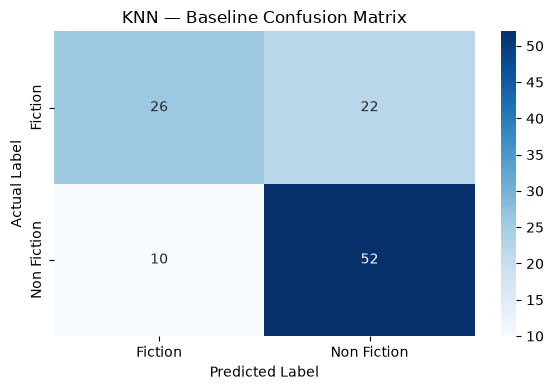

In [31]:
knn_train_pred = knn_model.predict(X_train)
knn_test_pred = knn_model.predict(X_test)

knn_baseline_metrics = {
    "Train Accuracy": accuracy_score(y_train, knn_train_pred),
    "Test Accuracy": accuracy_score(y_test, knn_test_pred),
    "Precision": precision_score(y_test, knn_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, knn_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, knn_test_pred, average="weighted", zero_division=0)
}

display(pd.DataFrame([knn_baseline_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, knn_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, knn_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("KNN — Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## KNN — Validation

Five-fold stratified cross-validation is performed only on the training data using weighted F1-score. Fold scores, mean score, and standard deviation are reported.

### 5W Explanation

- **What:** Validate baseline KNN across five stratified folds.
- **Why:** KNN can be sensitive to which observations become neighbors, so validation is important.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline KNN test evaluation and before hyperparameter tuning.
- **Where:** Cross-validation uses only the training data; the test set remains untouched.


In [32]:
knn_cv_scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

knn_baseline_cv_mean = knn_cv_scores.mean()
knn_baseline_cv_std = knn_cv_scores.std()

print("Fold F1 Scores:", np.round(knn_cv_scores, 4))
print("Mean CV F1:", round(knn_baseline_cv_mean, 4))
print("CV Standard Deviation:", round(knn_baseline_cv_std, 4))

Fold F1 Scores: [0.6956 0.7893 0.8631 0.736  0.7036]
Mean CV F1: 0.7575
CV Standard Deviation: 0.0622


## KNN — Hyperparameter Tuning

The number of neighbors, voting weights, and distance power are tuned. GridSearchCV uses the same five-fold stratified validation and weighted F1-score.

### 5W Explanation

- **What:** Search for a stronger KNN configuration.
- **Why:** These settings directly control neighborhood size, voting behavior, and the distance metric.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline KNN validation.
- **Where:** The parameter search is performed only on the training data.


In [33]:
knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best Validation F1:", round(knn_grid.best_score_, 4))

Best Parameters: {'model__n_neighbors': 11, 'model__p': 1, 'model__weights': 'distance'}
Best Validation F1: 0.77


## KNN — Tuned Model Evaluation

The best estimator returned by GridSearchCV is evaluated with the same train/test metrics, classification report, confusion matrix heatmap, and five-fold validation used for the baseline.

### 5W Explanation

- **What:** Measure the tuned KNN using exactly the same evaluation framework.
- **Why:** Identical evaluation allows a fair baseline-vs-tuned comparison.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after KNN hyperparameter tuning.
- **Where:** Test metrics use the untouched test set; validation uses the training set.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,1.0,0.7636,0.7747,0.7636,0.7554,0.77,0.0286



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.82      0.58      0.68        48
 Non Fiction       0.74      0.90      0.81        62

    accuracy                           0.76       110
   macro avg       0.78      0.74      0.75       110
weighted avg       0.77      0.76      0.76       110



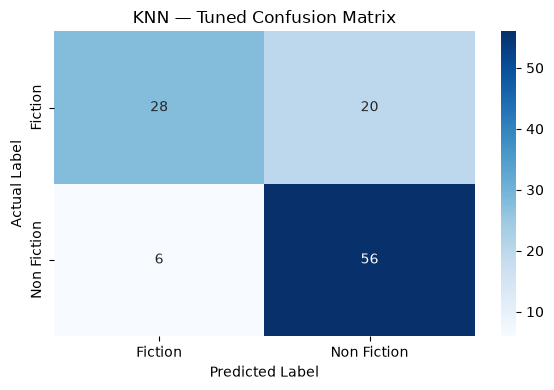

In [34]:
tuned_knn = knn_grid.best_estimator_

tuned_knn_train_pred = tuned_knn.predict(X_train)
tuned_knn_test_pred = tuned_knn.predict(X_test)

tuned_knn_cv_scores = cross_val_score(
    tuned_knn, X_train, y_train, cv=cv, scoring="f1_weighted"
)

knn_tuned_metrics = {
    "Train Accuracy": accuracy_score(y_train, tuned_knn_train_pred),
    "Test Accuracy": accuracy_score(y_test, tuned_knn_test_pred),
    "Precision": precision_score(y_test, tuned_knn_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, tuned_knn_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, tuned_knn_test_pred, average="weighted", zero_division=0),
    "CV F1 Mean": tuned_knn_cv_scores.mean(),
    "CV F1 Std": tuned_knn_cv_scores.std()
}

display(pd.DataFrame([knn_tuned_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_knn_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, tuned_knn_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("KNN — Tuned Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## KNN — Baseline vs Tuned Comparison

Baseline and tuned results are placed side by side across training accuracy, test metrics, and validation scores.

### 5W Explanation

- **What:** Compare KNN before and after tuning.
- **Why:** Tuning should be justified by measured improvement rather than assumed to help.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After tuned KNN evaluation.
- **Where:** The table uses metrics from the same data split and validation strategy.


,Version,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Baseline,0.8455,0.7091,0.7112,0.7091,0.7011,0.7575,0.0622
1,Tuned,1.0000,0.7636,0.7747,0.7636,0.7554,0.7700,0.0286


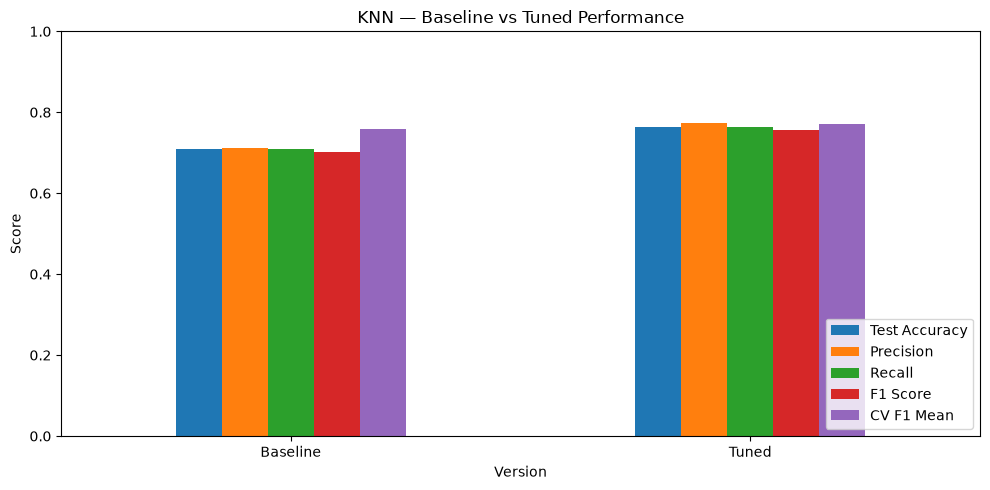

In [35]:
knn_comparison = pd.DataFrame([
    {
        "Version": "Baseline",
        **knn_baseline_metrics,
        "CV F1 Mean": knn_baseline_cv_mean,
        "CV F1 Std": knn_baseline_cv_std
    },
    {
        "Version": "Tuned",
        **knn_tuned_metrics
    }
])

display(knn_comparison.round(4))

# Graph: Baseline vs Tuned Performance
knn_comparison_plot = knn_comparison.set_index("Version")[[
    "Test Accuracy", "Precision", "Recall", "F1 Score", "CV F1 Mean"
]]

knn_comparison_plot.plot(kind="bar", figsize=(10, 5))
plt.title("KNN — Baseline vs Tuned Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision After Model 2 — Why Move from KNN to Decision Tree?

The tuned KNN improves substantially over Logistic Regression, reaching approximately **0.7554 test F1** and **0.7700 mean CV F1**. However, its training accuracy reaches **1.0000**, which is a warning that the selected neighborhood configuration may be fitting the training observations too closely.

### Why We Are Not Staying with KNN

- KNN is clearly better than Logistic Regression, but it still does not prove that it is the best model.
- Perfect training accuracy with lower validation/test performance suggests **overfitting**.
- KNN can also be sensitive to neighborhood size, feature scaling, and the local distribution of observations.

### Why We Go to Decision Tree Next

A Decision Tree can learn explicit nonlinear threshold rules and interactions such as combinations of rating, price, reviews, and year. It does not depend on distance calculations, so it tests a very different type of nonlinear structure.

### 5W Explanation

- **What:** Evaluate whether KNN generalizes well enough and justify moving to a tree-based model.
- **Why:** KNN improves performance but shows signs of overfitting and may not capture rule-like feature interactions efficiently.
- **Who:** The ML engineer compares training, test, and cross-validation performance before proceeding.
- **When:** After KNN tuning and its baseline-vs-tuned comparison.
- **Where:** The decision uses the same training data, validation folds, and untouched test data.

**ML Engineer Decision:** KNN remains a strong candidate, but **we should test a different nonlinear family before stopping**. Continue to Decision Tree.


## Model 3 — Decision Tree: Baseline Model

A Decision Tree learns nonlinear if-then rules directly from the numerical features and does not require scaling.

### 5W Explanation

- **What:** Build and fit the baseline Decision Tree classifier.
- **Why:** It can capture nonlinear feature interactions that simpler models may miss.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Before evaluating, validating, and tuning Decision Tree.
- **Where:** The model is fitted on the fixed training set created above.


In [36]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree baseline model trained.")

Decision Tree baseline model trained.


## Decision Tree — Baseline Evaluation Metrics

The baseline model is evaluated with training accuracy, test accuracy, weighted precision, weighted recall, weighted F1-score, a class-wise classification report, and a confusion matrix heatmap.

### 5W Explanation

- **What:** Measure the baseline Decision Tree on both training and unseen test data.
- **Why:** Multiple metrics provide a fuller picture than accuracy alone, while the train-test gap helps reveal overfitting or underfitting.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after fitting baseline Decision Tree.
- **Where:** Predictions are generated from the fixed training and test sets.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,1.0,0.7545,0.7541,0.7545,0.7542



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.72      0.71      0.72        48
 Non Fiction       0.78      0.79      0.78        62

    accuracy                           0.75       110
   macro avg       0.75      0.75      0.75       110
weighted avg       0.75      0.75      0.75       110



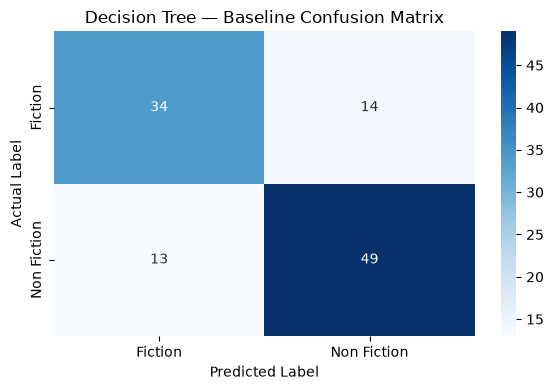

In [37]:
decision_tree_train_pred = decision_tree_model.predict(X_train)
decision_tree_test_pred = decision_tree_model.predict(X_test)

decision_tree_baseline_metrics = {
    "Train Accuracy": accuracy_score(y_train, decision_tree_train_pred),
    "Test Accuracy": accuracy_score(y_test, decision_tree_test_pred),
    "Precision": precision_score(y_test, decision_tree_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, decision_tree_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, decision_tree_test_pred, average="weighted", zero_division=0)
}

display(pd.DataFrame([decision_tree_baseline_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, decision_tree_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Decision Tree — Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Decision Tree — Validation

Five-fold stratified cross-validation is performed only on the training data using weighted F1-score. Fold scores, mean score, and standard deviation are reported.

### 5W Explanation

- **What:** Validate baseline Decision Tree across five stratified folds.
- **Why:** Decision Trees can have high variance, so fold-to-fold validation helps reveal instability.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Decision Tree test evaluation and before hyperparameter tuning.
- **Where:** Cross-validation uses only the training data; the test set remains untouched.


In [38]:
decision_tree_cv_scores = cross_val_score(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

decision_tree_baseline_cv_mean = decision_tree_cv_scores.mean()
decision_tree_baseline_cv_std = decision_tree_cv_scores.std()

print("Fold F1 Scores:", np.round(decision_tree_cv_scores, 4))
print("Mean CV F1:", round(decision_tree_baseline_cv_mean, 4))
print("CV Standard Deviation:", round(decision_tree_baseline_cv_std, 4))

Fold F1 Scores: [0.7127 0.7476 0.8182 0.83   0.7167]
Mean CV F1: 0.765
CV Standard Deviation: 0.0499


## Decision Tree — Hyperparameter Tuning

Criterion, maximum depth, minimum split size, and minimum leaf size are tuned. GridSearchCV uses the same five-fold stratified validation and weighted F1-score.

### 5W Explanation

- **What:** Search for a stronger Decision Tree configuration.
- **Why:** Controlling tree complexity can reduce overfitting while preserving useful nonlinear patterns.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Decision Tree validation.
- **Where:** The parameter search is performed only on the training data.


In [39]:
decision_tree_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

decision_tree_grid = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=decision_tree_param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

decision_tree_grid.fit(X_train, y_train)

print("Best Parameters:", decision_tree_grid.best_params_)
print("Best Validation F1:", round(decision_tree_grid.best_score_, 4))

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best Validation F1: 0.7722


## Decision Tree — Tuned Model Evaluation

The best estimator returned by GridSearchCV is evaluated with the same train/test metrics, classification report, confusion matrix heatmap, and five-fold validation used for the baseline.

### 5W Explanation

- **What:** Measure the tuned Decision Tree using exactly the same evaluation framework.
- **Why:** Identical evaluation allows a fair baseline-vs-tuned comparison.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after Decision Tree hyperparameter tuning.
- **Where:** Test metrics use the untouched test set; validation uses the training set.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,0.9682,0.7364,0.7371,0.7364,0.7367,0.7722,0.0479



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.69      0.71      0.70        48
 Non Fiction       0.77      0.76      0.76        62

    accuracy                           0.74       110
   macro avg       0.73      0.73      0.73       110
weighted avg       0.74      0.74      0.74       110



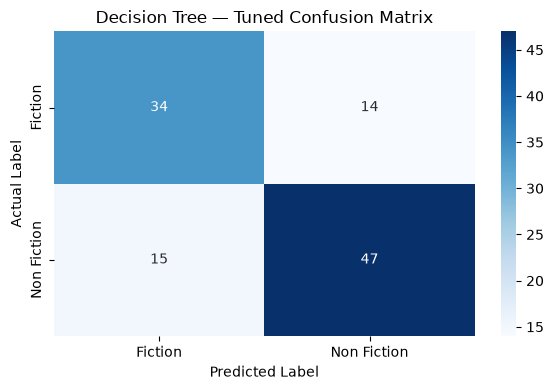

In [40]:
tuned_decision_tree = decision_tree_grid.best_estimator_

tuned_decision_tree_train_pred = tuned_decision_tree.predict(X_train)
tuned_decision_tree_test_pred = tuned_decision_tree.predict(X_test)

tuned_decision_tree_cv_scores = cross_val_score(
    tuned_decision_tree, X_train, y_train, cv=cv, scoring="f1_weighted"
)

decision_tree_tuned_metrics = {
    "Train Accuracy": accuracy_score(y_train, tuned_decision_tree_train_pred),
    "Test Accuracy": accuracy_score(y_test, tuned_decision_tree_test_pred),
    "Precision": precision_score(y_test, tuned_decision_tree_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, tuned_decision_tree_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, tuned_decision_tree_test_pred, average="weighted", zero_division=0),
    "CV F1 Mean": tuned_decision_tree_cv_scores.mean(),
    "CV F1 Std": tuned_decision_tree_cv_scores.std()
}

display(pd.DataFrame([decision_tree_tuned_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_decision_tree_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, tuned_decision_tree_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Decision Tree — Tuned Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Decision Tree — Baseline vs Tuned Comparison

Baseline and tuned results are placed side by side across training accuracy, test metrics, and validation scores.

### 5W Explanation

- **What:** Compare Decision Tree before and after tuning.
- **Why:** Tuning should be justified by measured improvement rather than assumed to help.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After tuned Decision Tree evaluation.
- **Where:** The table uses metrics from the same data split and validation strategy.


,Version,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Baseline,1.0000,0.7545,0.7541,0.7545,0.7542,0.7650,0.0499
1,Tuned,0.9682,0.7364,0.7371,0.7364,0.7367,0.7722,0.0479


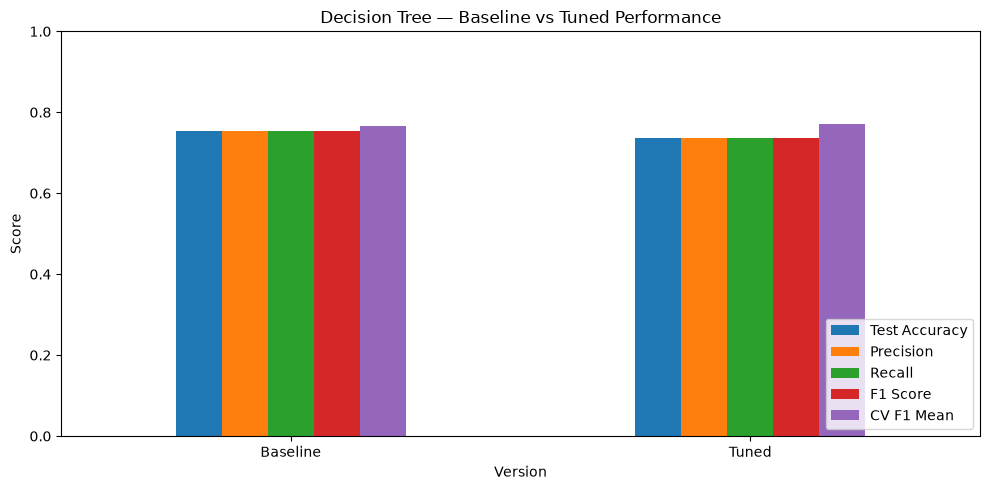

In [41]:
decision_tree_comparison = pd.DataFrame([
    {
        "Version": "Baseline",
        **decision_tree_baseline_metrics,
        "CV F1 Mean": decision_tree_baseline_cv_mean,
        "CV F1 Std": decision_tree_baseline_cv_std
    },
    {
        "Version": "Tuned",
        **decision_tree_tuned_metrics
    }
])

display(decision_tree_comparison.round(4))

# Graph: Baseline vs Tuned Performance
decision_tree_comparison_plot = decision_tree_comparison.set_index("Version")[[
    "Test Accuracy", "Precision", "Recall", "F1 Score", "CV F1 Mean"
]]

decision_tree_comparison_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Decision Tree — Baseline vs Tuned Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision After Model 3 — Why Move from Decision Tree to Random Forest?

The Decision Tree can fit complicated nonlinear rules, but its baseline training accuracy is **1.0000** while test performance is much lower. After tuning, mean CV F1 improves slightly to approximately **0.7722**, but test F1 is around **0.7367**. This is typical evidence that one tree can have high variance and be sensitive to the exact training sample.

### Why We Are Not Staying with One Decision Tree

- A single tree can memorize training patterns and overfit.
- Its performance can change noticeably when the training sample changes.
- Tuning reduces complexity, but the test performance still does not clearly beat KNN.

### Why We Go to Random Forest Next

Random Forest directly addresses the main weakness of a single Decision Tree. Instead of relying on one tree, it combines many trees trained on different samples/features and averages their decisions. This usually **reduces variance and improves generalization** while keeping the ability to model nonlinear relationships.

### 5W Explanation

- **What:** Decide whether a single tree is reliable enough and justify using an ensemble of trees next.
- **Why:** The Decision Tree shows overfitting/instability, and Random Forest is specifically designed to reduce this weakness.
- **Who:** The ML engineer interprets the train-test gap, CV score, and tuned result.
- **When:** After completing the Decision Tree comparison.
- **Where:** Random Forest is evaluated on exactly the same split so the comparison stays fair.

**ML Engineer Decision:** Do not stop at one Decision Tree. Move to **Random Forest** to retain nonlinear power while reducing tree variance.


## Model 4 — Random Forest: Baseline Model

Random Forest combines many decision trees to reduce variance while keeping nonlinear modeling ability.

### 5W Explanation

- **What:** Build and fit the baseline Random Forest classifier.
- **Why:** An ensemble can generalize better than a single tree while handling complex feature interactions.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Before evaluating, validating, and tuning Random Forest.
- **Where:** The model is fitted on the fixed training set created above.


In [42]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest baseline model trained.")

Random Forest baseline model trained.


## Random Forest — Baseline Evaluation Metrics

The baseline model is evaluated with training accuracy, test accuracy, weighted precision, weighted recall, weighted F1-score, a class-wise classification report, and a confusion matrix heatmap.

### 5W Explanation

- **What:** Measure the baseline Random Forest on both training and unseen test data.
- **Why:** Multiple metrics provide a fuller picture than accuracy alone, while the train-test gap helps reveal overfitting or underfitting.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after fitting baseline Random Forest.
- **Where:** Predictions are generated from the fixed training and test sets.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,1.0,0.7909,0.798,0.7909,0.7859



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.84      0.65      0.73        48
 Non Fiction       0.77      0.90      0.83        62

    accuracy                           0.79       110
   macro avg       0.80      0.77      0.78       110
weighted avg       0.80      0.79      0.79       110



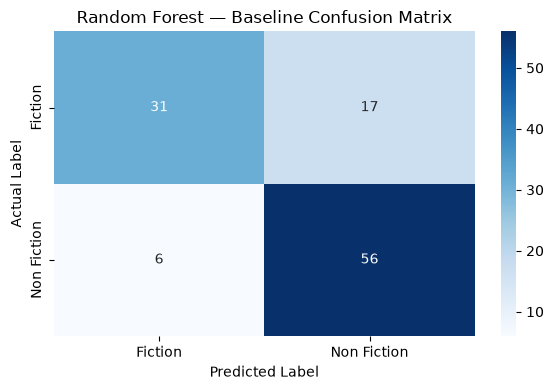

In [43]:
random_forest_train_pred = random_forest_model.predict(X_train)
random_forest_test_pred = random_forest_model.predict(X_test)

random_forest_baseline_metrics = {
    "Train Accuracy": accuracy_score(y_train, random_forest_train_pred),
    "Test Accuracy": accuracy_score(y_test, random_forest_test_pred),
    "Precision": precision_score(y_test, random_forest_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, random_forest_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, random_forest_test_pred, average="weighted", zero_division=0)
}

display(pd.DataFrame([random_forest_baseline_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, random_forest_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, random_forest_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Random Forest — Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Random Forest — Validation

Five-fold stratified cross-validation is performed only on the training data using weighted F1-score. Fold scores, mean score, and standard deviation are reported.

### 5W Explanation

- **What:** Validate baseline Random Forest across five stratified folds.
- **Why:** Validation checks whether strong ensemble performance is consistent across training folds.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Random Forest test evaluation and before hyperparameter tuning.
- **Where:** Cross-validation uses only the training data; the test set remains untouched.


In [44]:
random_forest_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

random_forest_baseline_cv_mean = random_forest_cv_scores.mean()
random_forest_baseline_cv_std = random_forest_cv_scores.std()

print("Fold F1 Scores:", np.round(random_forest_cv_scores, 4))
print("Mean CV F1:", round(random_forest_baseline_cv_mean, 4))
print("CV Standard Deviation:", round(random_forest_baseline_cv_std, 4))

Fold F1 Scores: [0.7319 0.7636 0.8859 0.7732 0.8404]
Mean CV F1: 0.799
CV Standard Deviation: 0.056


## Random Forest — Hyperparameter Tuning

The number of trees, depth, split size, leaf size, and feature-sampling rule are tuned. GridSearchCV uses the same five-fold stratified validation and weighted F1-score.

### 5W Explanation

- **What:** Search for a stronger Random Forest configuration.
- **Why:** These settings control ensemble capacity and the bias-variance trade-off.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline Random Forest validation.
- **Where:** The parameter search is performed only on the training data.


In [45]:
random_forest_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

random_forest_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=random_forest_param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

random_forest_grid.fit(X_train, y_train)

print("Best Parameters:", random_forest_grid.best_params_)
print("Best Validation F1:", round(random_forest_grid.best_score_, 4))

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best Validation F1: 0.8097


## Random Forest — Tuned Model Evaluation

The best estimator returned by GridSearchCV is evaluated with the same train/test metrics, classification report, confusion matrix heatmap, and five-fold validation used for the baseline.

### 5W Explanation

- **What:** Measure the tuned Random Forest using exactly the same evaluation framework.
- **Why:** Identical evaluation allows a fair baseline-vs-tuned comparison.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after Random Forest hyperparameter tuning.
- **Where:** Test metrics use the untouched test set; validation uses the training set.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,0.9773,0.8091,0.8138,0.8091,0.8057,0.8097,0.0619



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.85      0.69      0.76        48
 Non Fiction       0.79      0.90      0.84        62

    accuracy                           0.81       110
   macro avg       0.82      0.80      0.80       110
weighted avg       0.81      0.81      0.81       110



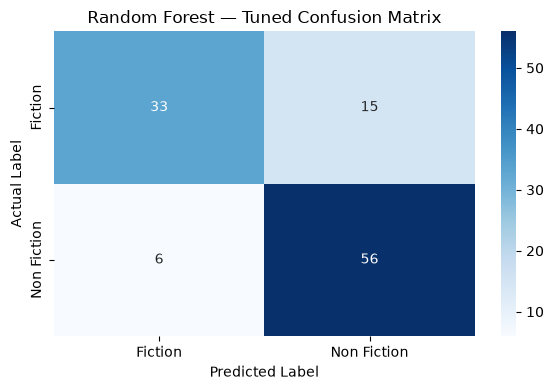

In [46]:
tuned_random_forest = random_forest_grid.best_estimator_

tuned_random_forest_train_pred = tuned_random_forest.predict(X_train)
tuned_random_forest_test_pred = tuned_random_forest.predict(X_test)

tuned_random_forest_cv_scores = cross_val_score(
    tuned_random_forest, X_train, y_train, cv=cv, scoring="f1_weighted"
)

random_forest_tuned_metrics = {
    "Train Accuracy": accuracy_score(y_train, tuned_random_forest_train_pred),
    "Test Accuracy": accuracy_score(y_test, tuned_random_forest_test_pred),
    "Precision": precision_score(y_test, tuned_random_forest_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, tuned_random_forest_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, tuned_random_forest_test_pred, average="weighted", zero_division=0),
    "CV F1 Mean": tuned_random_forest_cv_scores.mean(),
    "CV F1 Std": tuned_random_forest_cv_scores.std()
}

display(pd.DataFrame([random_forest_tuned_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_random_forest_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, tuned_random_forest_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Random Forest — Tuned Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Random Forest — Baseline vs Tuned Comparison

Baseline and tuned results are placed side by side across training accuracy, test metrics, and validation scores.

### 5W Explanation

- **What:** Compare Random Forest before and after tuning.
- **Why:** Tuning should be justified by measured improvement rather than assumed to help.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After tuned Random Forest evaluation.
- **Where:** The table uses metrics from the same data split and validation strategy.


,Version,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Baseline,1.0000,0.7909,0.7980,0.7909,0.7859,0.7990,0.0560
1,Tuned,0.9773,0.8091,0.8138,0.8091,0.8057,0.8097,0.0619


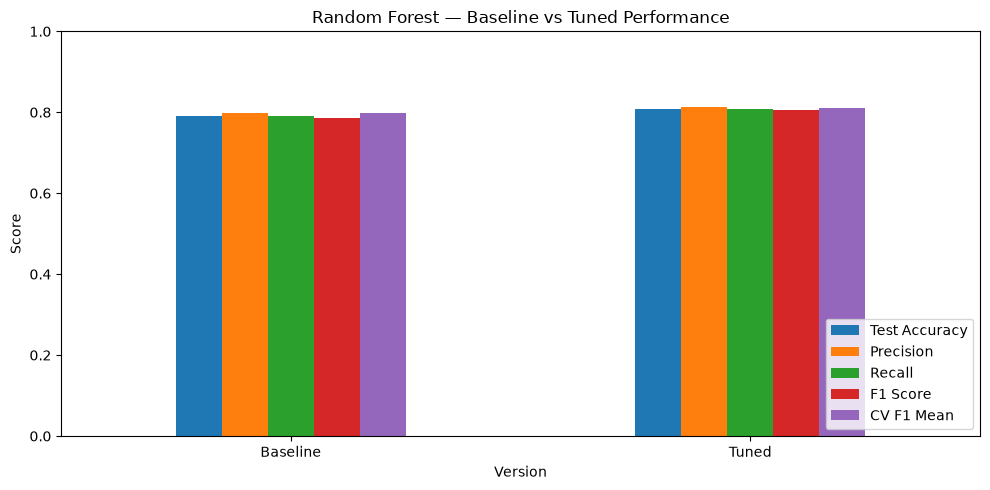

In [47]:
random_forest_comparison = pd.DataFrame([
    {
        "Version": "Baseline",
        **random_forest_baseline_metrics,
        "CV F1 Mean": random_forest_baseline_cv_mean,
        "CV F1 Std": random_forest_baseline_cv_std
    },
    {
        "Version": "Tuned",
        **random_forest_tuned_metrics
    }
])

display(random_forest_comparison.round(4))

# Graph: Baseline vs Tuned Performance
random_forest_comparison_plot = random_forest_comparison.set_index("Version")[[
    "Test Accuracy", "Precision", "Recall", "F1 Score", "CV F1 Mean"
]]

random_forest_comparison_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Random Forest — Baseline vs Tuned Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision After Model 4 — Why Test SVM Even Though Random Forest Is Strong?

The tuned Random Forest is currently the strongest model, with approximately **0.8057 test F1** and **0.8097 mean CV F1**. It also improves on the single Decision Tree, which supports the idea that combining many trees reduces variance.

### Why We Do Not Stop Immediately at Random Forest

Random Forest is leading, but good model selection should not stop as soon as one model looks strong. We still have one planned algorithm from a completely different model family. Testing it helps us verify that the apparent winner is not simply the best among the models tried so far.

### Why We Go to SVM Next

SVM creates a maximum-margin decision boundary and, with an RBF kernel, can model smooth nonlinear class separation. It therefore provides an important contrast to tree ensembles. If SVM performs better in cross-validation, it could become the preferred model; if it does not, our confidence in Random Forest increases.

### 5W Explanation

- **What:** Keep Random Forest as the current leader but test SVM before final selection.
- **Why:** Comparing different model families reduces the risk of choosing a model prematurely.
- **Who:** The ML engineer follows the pre-defined five-model comparison plan.
- **When:** After Random Forest evaluation and tuning but before final model selection.
- **Where:** SVM uses the same training/test split and validation strategy for an apples-to-apples comparison.

**ML Engineer Decision:** Random Forest is the **current best candidate**, but complete the experiment by testing SVM.


## Model 5 — Support Vector Machine (SVM): Baseline Model

SVM uses a margin-based decision boundary. The baseline uses an RBF kernel and scaling is applied inside a pipeline.

### 5W Explanation

- **What:** Build and fit the baseline SVM classifier.
- **Why:** It provides a flexible nonlinear margin-based alternative to trees and nearest-neighbor models.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Before evaluating, validating, and tuning SVM.
- **Where:** The model is fitted on the fixed training set created above.


In [48]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf"))
])

svm_model.fit(X_train, y_train)

print("SVM baseline model trained.")

SVM baseline model trained.


## SVM — Baseline Evaluation Metrics

The baseline model is evaluated with training accuracy, test accuracy, weighted precision, weighted recall, weighted F1-score, a class-wise classification report, and a confusion matrix heatmap.

### 5W Explanation

- **What:** Measure the baseline SVM on both training and unseen test data.
- **Why:** Multiple metrics provide a fuller picture than accuracy alone, while the train-test gap helps reveal overfitting or underfitting.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after fitting baseline SVM.
- **Where:** Predictions are generated from the fixed training and test sets.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,0.7977,0.7727,0.7735,0.7727,0.7699



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.78      0.67      0.72        48
 Non Fiction       0.77      0.85      0.81        62

    accuracy                           0.77       110
   macro avg       0.77      0.76      0.76       110
weighted avg       0.77      0.77      0.77       110



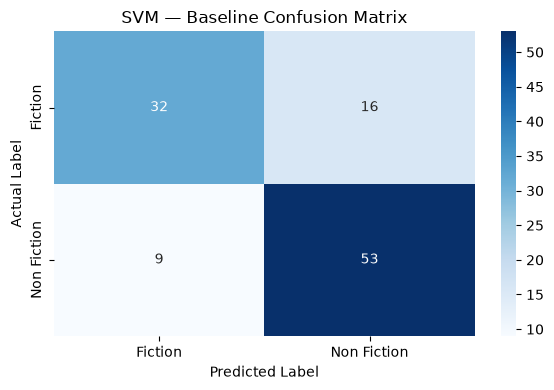

In [49]:
svm_train_pred = svm_model.predict(X_train)
svm_test_pred = svm_model.predict(X_test)

svm_baseline_metrics = {
    "Train Accuracy": accuracy_score(y_train, svm_train_pred),
    "Test Accuracy": accuracy_score(y_test, svm_test_pred),
    "Precision": precision_score(y_test, svm_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, svm_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, svm_test_pred, average="weighted", zero_division=0)
}

display(pd.DataFrame([svm_baseline_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, svm_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, svm_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("SVM — Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## SVM — Validation

Five-fold stratified cross-validation is performed only on the training data using weighted F1-score. Fold scores, mean score, and standard deviation are reported.

### 5W Explanation

- **What:** Validate baseline SVM across five stratified folds.
- **Why:** Validation estimates whether SVM performance is stable beyond one train-test split.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline SVM test evaluation and before hyperparameter tuning.
- **Where:** Cross-validation uses only the training data; the test set remains untouched.


In [50]:
svm_cv_scores = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

svm_baseline_cv_mean = svm_cv_scores.mean()
svm_baseline_cv_std = svm_cv_scores.std()

print("Fold F1 Scores:", np.round(svm_cv_scores, 4))
print("Mean CV F1:", round(svm_baseline_cv_mean, 4))
print("CV Standard Deviation:", round(svm_baseline_cv_std, 4))

Fold F1 Scores: [0.7108 0.7233 0.8409 0.7819 0.6708]
Mean CV F1: 0.7456
CV Standard Deviation: 0.0595


## SVM — Hyperparameter Tuning

Regularization `C`, kernel type, and gamma are tuned. GridSearchCV uses the same five-fold stratified validation and weighted F1-score.

### 5W Explanation

- **What:** Search for a stronger SVM configuration.
- **Why:** These parameters control margin strength and nonlinear boundary flexibility.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After baseline SVM validation.
- **Where:** The parameter search is performed only on the training data.


In [51]:
svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    estimator=svm_model,
    param_grid=svm_param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best Parameters:", svm_grid.best_params_)
print("Best Validation F1:", round(svm_grid.best_score_, 4))

Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best Validation F1: 0.7456


## SVM — Tuned Model Evaluation

The best estimator returned by GridSearchCV is evaluated with the same train/test metrics, classification report, confusion matrix heatmap, and five-fold validation used for the baseline.

### 5W Explanation

- **What:** Measure the tuned SVM using exactly the same evaluation framework.
- **Why:** Identical evaluation allows a fair baseline-vs-tuned comparison.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after SVM hyperparameter tuning.
- **Where:** Test metrics use the untouched test set; validation uses the training set.

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,0.7977,0.7727,0.7735,0.7727,0.7699,0.7456,0.0595



Classification Report:
              precision    recall  f1-score   support

     Fiction       0.78      0.67      0.72        48
 Non Fiction       0.77      0.85      0.81        62

    accuracy                           0.77       110
   macro avg       0.77      0.76      0.76       110
weighted avg       0.77      0.77      0.77       110



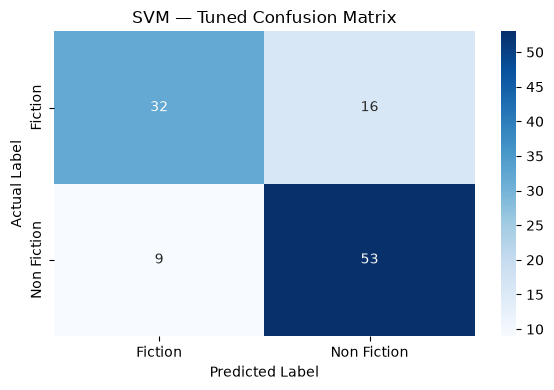

In [ ]:
tuned_svm = svm_grid.best_estimator_

tuned_svm_train_pred = tuned_svm.predict(X_train)
tuned_svm_test_pred = tuned_svm.predict(X_test)

tuned_svm_cv_scores = cross_val_score(
    tuned_svm, X_train, y_train, cv=cv, scoring="f1_weighted"
)

svm_tuned_metrics = {
    "Train Accuracy": accuracy_score(y_train, tuned_svm_train_pred),
    "Test Accuracy": accuracy_score(y_test, tuned_svm_test_pred),
    "Precision": precision_score(y_test, tuned_svm_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, tuned_svm_test_pred, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test, tuned_svm_test_pred, average="weighted", zero_division=0),
    "CV F1 Mean": tuned_svm_cv_scores.mean(),
    "CV F1 Std": tuned_svm_cv_scores.std()
}

display(pd.DataFrame([svm_tuned_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_svm_test_pred))

# Confusion Matrix Heatmap
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, tuned_svm_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("SVM — Tuned Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## SVM — Baseline vs Tuned Comparison

Baseline and tuned results are placed side by side across training accuracy, test metrics, and validation scores.

### 5W Explanation

- **What:** Compare SVM before and after tuning.
- **Why:** Tuning should be justified by measured improvement rather than assumed to help.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After tuned SVM evaluation.
- **Where:** The table uses metrics from the same data split and validation strategy.


,Version,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Baseline,0.7977,0.7727,0.7735,0.7727,0.7699,0.7456,0.0595
1,Tuned,0.7977,0.7727,0.7735,0.7727,0.7699,0.7456,0.0595


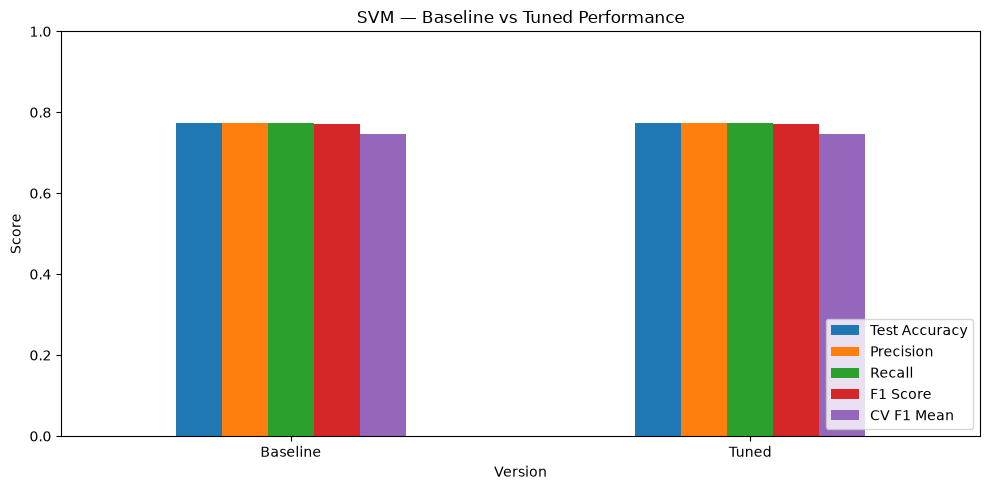

In [53]:
svm_comparison = pd.DataFrame([
    {
        "Version": "Baseline",
        **svm_baseline_metrics,
        "CV F1 Mean": svm_baseline_cv_mean,
        "CV F1 Std": svm_baseline_cv_std
    },
    {
        "Version": "Tuned",
        **svm_tuned_metrics
    }
])

display(svm_comparison.round(4))

# Graph: Baseline vs Tuned Performance
svm_comparison_plot = svm_comparison.set_index("Version")[[
    "Test Accuracy", "Precision", "Recall", "F1 Score", "CV F1 Mean"
]]

svm_comparison_plot.plot(kind="bar", figsize=(10, 5))
plt.title("SVM — Baseline vs Tuned Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision After Model 5 — Why We Do Not Stay with SVM

The tuned SVM achieves approximately **0.7699 test F1** and **0.7456 mean CV F1**. Its performance is respectable, but its validation score is lower than Random Forest and also lower than the best validation results from KNN/Decision Tree. Tuning does not materially improve the baseline SVM in this experiment.

### Why We Are Not Selecting SVM

- SVM does not beat Random Forest on the main ranking metric, mean cross-validation F1.
- Its tuned test F1 is also below Random Forest.
- Since every model was evaluated on the same split and validation framework, there is no evidence-based reason to prefer SVM over the stronger Random Forest result.

### What Happens Next

All five planned classical models are now complete. We can move to the final comparison table and select the model with the strongest combination of cross-validation and unseen-test performance.

### 5W Explanation

- **What:** Conclude the SVM experiment and move to final model comparison.
- **Why:** SVM is useful as a different nonlinear model family, but it does not outperform the current leader.
- **Who:** The ML engineer makes the final comparison using consistent metrics.
- **When:** After SVM validation and tuning are complete.
- **Where:** The decision uses results from all five models trained and evaluated on the same dataset split.

**ML Engineer Decision:** Do not select SVM. Proceed to the final five-model comparison, with Random Forest currently leading.


## Final Comparison — All Five Tuned Models

The tuned version of every algorithm is combined into one table. **Mean cross-validation weighted F1 is the primary ranking metric**, while test F1 and the training-test gap are supporting evidence.

### 5W Explanation

- **What:** Compare all five tuned models with one consistent metric table.
- **Why:** A common final table makes model selection transparent and avoids choosing from one isolated score.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After all five models have completed their separate workflows.
- **Where:** The table combines results from the common training data, validation folds, and untouched test set.


In [54]:
final_results = pd.DataFrame([
    {"Model": "Logistic Regression", **logistic_tuned_metrics},
    {"Model": "KNN", **knn_tuned_metrics},
    {"Model": "Decision Tree", **decision_tree_tuned_metrics},
    {"Model": "Random Forest", **random_forest_tuned_metrics},
    {"Model": "SVM", **svm_tuned_metrics}
])

final_results = final_results.sort_values(
    by=["CV F1 Mean", "F1 Score"],
    ascending=False
).reset_index(drop=True)

display(final_results.round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Random Forest,0.9773,0.8091,0.8138,0.8091,0.8057,0.8097,0.0619
1,Decision Tree,0.9682,0.7364,0.7371,0.7364,0.7367,0.7722,0.0479
2,KNN,1.0000,0.7636,0.7747,0.7636,0.7554,0.7700,0.0286
3,SVM,0.7977,0.7727,0.7735,0.7727,0.7699,0.7456,0.0595
4,Logistic Regression,0.6818,0.6091,0.6026,0.6091,0.5970,0.6800,0.0370


## Visual Comparison of All Tuned Models

A bar chart compares test weighted F1 and mean cross-validation weighted F1 for all five tuned classifiers.

### 5W Explanation

- **What:** Visualize the two most important generalization scores for every model.
- **Why:** The chart makes relative performance easier to interpret than a table alone.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After the final comparison table.
- **Where:** The chart is generated from `final_results`.


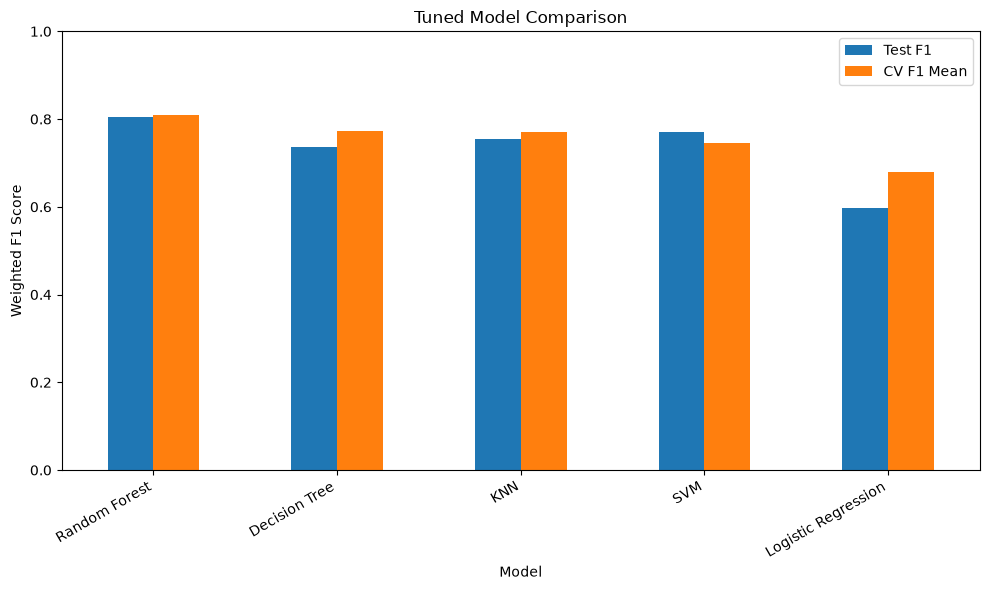

In [55]:
comparison_plot = final_results.set_index("Model")[["F1 Score", "CV F1 Mean"]]

comparison_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Tuned Model Comparison")
plt.ylabel("Weighted F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(["Test F1", "CV F1 Mean"])
plt.tight_layout()
plt.show()

## Best Model Selection

The model with the highest mean cross-validation F1-score is selected, with unseen test F1 used as supporting evidence. For the supplied dataset and fixed split, the tuned **Random Forest** is the strongest overall candidate.

### 5W Explanation

- **What:** Select the final classifier from the five tuned models.
- **Why:** Cross-validation reduces dependence on one split and the test result confirms unseen-data performance.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After all tuned models have been compared.
- **Where:** The selection is made from `final_results`.


In [56]:
tuned_models = {
    "Logistic Regression": tuned_logistic,
    "KNN": tuned_knn,
    "Decision Tree": tuned_decision_tree,
    "Random Forest": tuned_random_forest,
    "SVM": tuned_svm
}

best_model_name = final_results.loc[0, "Model"]
best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)
display(final_results.iloc[[0]].round(4))

Best Model: Random Forest


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std
0,Random Forest,0.9773,0.8091,0.8138,0.8091,0.8057,0.8097,0.0619


## Best Model — Final Classification Report and Confusion Matrix

The selected model is examined one final time at the class level on the unseen test set.

### 5W Explanation

- **What:** Display class-wise precision, recall, F1-score, and the confusion matrix heatmap for the final model.
- **Why:** Overall scores can hide class-specific weaknesses, so this is an important final diagnostic.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** Immediately after best-model selection.
- **Where:** The diagnostic uses the untouched test set.

Final Classification Report:
              precision    recall  f1-score   support

     Fiction       0.85      0.69      0.76        48
 Non Fiction       0.79      0.90      0.84        62

    accuracy                           0.81       110
   macro avg       0.82      0.80      0.80       110
weighted avg       0.81      0.81      0.81       110



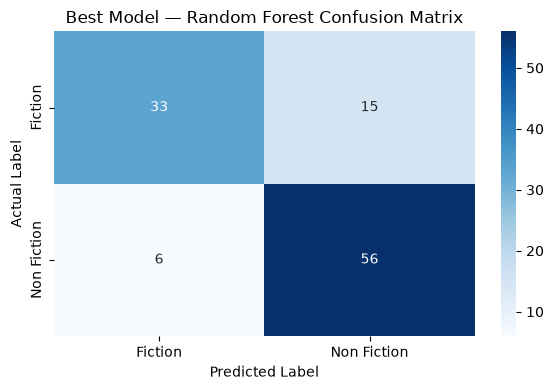

In [ ]:
best_model_test_pred = best_model.predict(X_test)

print("Final Classification Report:")
print(classification_report(y_test, best_model_test_pred))
labels = sorted(y_test.unique())
final_cm = confusion_matrix(y_test, best_model_test_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f"Best Model — {best_model_name} Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Prediction on New / Unseen Data

A new sample book is created using the same four selected features. Raw Reviews are converted to `Reviews_Log` using `np.log1p()` before prediction.

### 5W Explanation

- **What:** Demonstrate how the selected model predicts a genre for unseen book information.
- **Why:** A sample prediction proves the workflow is usable beyond the training dataset.
- **Who:** An analyst or future application can provide new book values and receive a predicted genre.
- **When:** After final model selection and evaluation.
- **Where:** The new observation uses the same feature names and transformation as the training data.


In [58]:
new_book = pd.DataFrame({
    "User Rating": [4.7],
    "Reviews_Log": [np.log1p(15000)],
    "Price": [15],
    "Year": [2020]
})

prediction = best_model.predict(new_book)
print("Predicted Genre:", prediction[0])

Predicted Genre: Non Fiction


## Reusable Prediction Function

A helper function accepts raw book information, applies the required review transformation, and returns the predicted genre.

### 5W Explanation

- **What:** Create a reusable interface for future predictions.
- **Why:** The function reduces repeated code and ensures the same preprocessing is applied.
- **Who:** An analyst or application user can call the function.
- **When:** After the final input format is confirmed.
- **Where:** The function runs inside the notebook and uses `best_model`.


In [59]:
def predict_genre(user_rating, reviews, price, year):
    book = pd.DataFrame({
        "User Rating": [user_rating],
        "Reviews_Log": [np.log1p(reviews)],
        "Price": [price],
        "Year": [year]
    })
    return best_model.predict(book)[0]

print("Sample Prediction:", predict_genre(4.7, 15000, 15, 2020))

Sample Prediction: Non Fiction


## Automatic Prediction Using the Saved Best Model

After comparing all five machine learning algorithms, the **Tuned Random Forest model** was selected as the final model because it achieved the best overall Test F1 Score and Cross-Validation F1 Score.

For the final prediction, we will **not manually enter values** such as User Rating, Reviews, Price, or Year.

Instead, the program will automatically select an unseen observation from the test dataset and send its feature values directly to the saved Random Forest model.

This makes the prediction process more realistic because the model receives data automatically rather than depending on manually entered values.

### 5W Explanation

* **What:** Automatically select an unseen record and predict its Genre using the saved Random Forest model.
* **Why:** Manual input is not required because the test dataset already contains observations that were not used for training.
* **Who:** The saved machine learning model performs the final prediction automatically.
* **When:** After selecting the best model, completing hyperparameter tuning, and saving the final model.
* **Where:** The input observation is automatically taken from `X_test`, which contains unseen testing records.



## Saving the Final Model

The selected model is saved with Joblib as `bestseller_genre_model.pkl`.

### 5W Explanation

- **What:** Persist the fitted classifier so it can be reused without retraining.
- **Why:** Saving the model is a standard final step for reuse or deployment.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** After model selection and sample prediction.
- **Where:** The serialized model is written from the notebook environment.


In [60]:
joblib.dump(
    best_model,
    "bestseller_genre_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [61]:
loaded_model = joblib.load("bestseller_genre_model.pkl")

print("Model loaded successfully.")

Model loaded successfully.


## Automatically Selecting an Unseen Input

Instead of manually giving feature values, one observation is automatically selected from the testing dataset.

The selected record contains the same input features used during model training:

* User Rating
* Reviews_Log
* Price
* Year

The user does not need to type or provide any values.

### 5W Explanation

* **What:** Automatically select one unseen observation from `X_test`.
* **Why:** To demonstrate prediction without manually creating input values.
* **Who:** The Python program automatically selects the observation.
* **When:** After loading the saved model.
* **Where:** The observation is selected directly from the test dataset.


In [ ]:
sample_input = X_test.sample(n=1, random_state=42)

print("Automatically selected input:")
display(sample_input)

Automatically selected input:


,User Rating,Reviews_Log,Price,Year
536,4.6,8.805375,12,2018


## Predicting the Output Using the Saved Model

The automatically selected observation is passed directly to the loaded Random Forest model.

The model then predicts whether the book belongs to the **Fiction** or **Non Fiction** Genre.

No manual input is provided.

### 5W Explanation

* **What:** Predict the Genre of the automatically selected observation.
* **Why:** To check how the saved model predicts unseen data.
* **Who:** The loaded Random Forest model performs the prediction.
* **When:** After automatically selecting an input observation.
* **Where:** Prediction is performed using the feature values selected from `X_test`.


In [ ]:
predicted_genre = loaded_model.predict(sample_input)

print("Predicted Genre:", predicted_genre[0])

Predicted Genre: Non Fiction


## Comparing Actual and Predicted Output

Because the observation comes from the test dataset, its actual Genre is already available in `y_test`.

We can therefore compare the model's prediction with the real output.

This provides a simple final demonstration of the model's prediction capability.

### 5W Explanation

* **What:** Compare the actual Genre with the predicted Genre.
* **Why:** To verify whether the model correctly classified the automatically selected unseen observation.
* **Who:** The ML engineer evaluates the prediction produced by the saved model.
* **When:** Immediately after performing the final prediction.
* **Where:** The actual value comes from `y_test`, while the prediction comes from the saved Random Forest model.


In [ ]:
sample_index = sample_input.index[0]
actual_genre = y_test.loc[sample_index]
predicted_genre = loaded_model.predict(sample_input)[0]

print("Actual Genre    :", actual_genre)
print("Predicted Genre :", predicted_genre)

Actual Genre    : Non Fiction
Predicted Genre : Non Fiction


## Final Conclusion

The original data-understanding, cleaning, EDA, feature-engineering, feature-selection, and train-test-split **code logic is kept unchanged**. The markdown before the split is expanded only to include the requested 5Ws.

After the split, Logistic Regression, KNN, Decision Tree, Random Forest, and SVM are each handled separately with baseline evaluation, stratified five-fold validation, GridSearchCV hyperparameter tuning, tuned evaluation, and baseline-vs-tuned comparison.

On the supplied data with `random_state=42`, the tuned **Random Forest** is the strongest overall model. It achieves approximately **0.8097 mean cross-validation weighted F1** and **0.8057 weighted test F1**. This provides the best balance of validation and unseen-test performance among the five candidates.

The experiment also shows why training accuracy alone should not decide the winner: some tree-based models fit the training data extremely strongly, so validation and test metrics are more useful evidence of generalization.

### 5W Explanation

- **What:** Summarize the complete experiment and identify tuned Random Forest as the best overall model.
- **Why:** The conclusion connects preprocessing, validation, tuning, and comparison evidence into one clear decision.
- **Who:** The data analyst / machine-learning engineer performs and reviews this step.
- **When:** At the end of the complete machine-learning workflow.
- **Where:** The conclusion applies to the supplied Amazon bestseller dataset, selected four predictors, fixed split, and five-model experiment.

### Why This Model Progression Was Important

The five models were not tried randomly. Each new model tested a limitation observed in the previous family: linear boundary → local nonlinear neighbors → rule-based nonlinear tree → lower-variance tree ensemble → margin-based nonlinear SVM. This progression makes the final Random Forest choice evidence-based rather than arbitrary.

Deep learning was deliberately excluded because the dataset is very small and low-dimensional. A deeper neural network would add many parameters and tuning decisions without a clear data advantage, increasing overfitting risk rather than automatically improving generalization.